# Projet Data Mining - 01. Audit exploratoire des données

**Objectif :** partir du CSV brut pour documenter les identifiants répétés, l'exemple `id = 72521`, le segment final atypique et les valeurs manquantes de `SEXE`.

Ce notebook est **indépendant** du notebook précédent : aucune suppression, aucune imputation, aucune hypothèse non vérifiée sur la chronologie des observations. Les conclusions restent provisoires jusqu'à confirmation de l'enseignant.

## 1. Chargement et intégrité du jeu de données

Le fichier source n'est jamais écrasé. On conserve un contrôle de son empreinte SHA-256 pour assurer la reproductibilité.

In [1]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

candidats = [Path('../data/données.csv'), Path('data/données.csv')]
chemin = next((p for p in candidats if p.exists()), None)
if chemin is None:
    raise FileNotFoundError('Placer données.csv dans le dossier data/ du projet.')

df = pd.read_csv(chemin, sep=';')
produits = [c for c in df.columns if c not in ('id', 'SEXE')]
print(f'Fichier : {chemin.resolve()}')
print(f'SHA-256 : {hashlib.sha256(chemin.read_bytes()).hexdigest()}')
print(f'Dimensions : {df.shape}; variables produits : {len(produits)}')
display(df.head())

Fichier : C:\Users\SebastianAraya\Documents\Documentos\LILLE\Master\3S\Data Mining\projet-data-mining\data\données.csv
SHA-256 : 74ee69ed105c39a8b9d3b4c553134a4c0d851f3ef6f519740d7bc9ab3179a1aa
Dimensions : (73930, 28); variables produits : 26


,CART,CJEU,PACKSERV,DAV,DECAUTH,CPAI,CARTE,SEXE,auto,GAV,...,CREDHAB,CSL,OBLIGATION,SICAVFCP,EPARBANC,ASSPREVDEC,ASSDEP,CREDRENOV,ASSPREVDECDEP,id
0,0,0,0,1,0,0,0,NaN,1,0,...,0,1,0,0,1,0,0,0,0,1
1,1,0,1,1,0,1,0,NaN,1,1,...,0,1,0,1,1,0,0,0,0,2
2,1,1,1,1,1,1,0,M,0,1,...,0,1,0,0,0,0,0,0,0,3
3,1,0,1,1,1,1,0,F,0,1,...,0,1,0,0,0,0,0,0,0,4
4,1,0,0,1,0,1,0,F,0,1,...,0,1,0,0,0,0,0,0,0,5


## 2. Contrôles de structure

L'unité statistique reste à confirmer : un `id` peut-il être associé à plusieurs observations, ou doit-il être unique ?

In [2]:
assert {'id', 'SEXE'}.issubset(df.columns)
assert len(produits) == 26
assert all(df[p].isin([0, 1]).all() for p in produits)

resume = pd.DataFrame({
    'indicateur': ['lignes', 'colonnes', 'id distincts', 'id répétés',
                   'lignes dupliquées exactement', 'valeurs manquantes SEXE'],
    'valeur': [len(df), df.shape[1], df['id'].nunique(),
               df['id'].value_counts().gt(1).sum(),
               df.duplicated().sum(), df['SEXE'].isna().sum()]
})
display(resume)

,indicateur,valeur
0,lignes,73930
1,colonnes,28
2,id distincts,72638
3,id répétés,118
4,lignes dupliquées exactement,1265
5,valeurs manquantes SEXE,1283


## 3. Identifiants répétés : trois cas à distinguer

- **Doublons exacts** : toutes les colonnes sont identiques pour un même `id`.
- **Conflit de `SEXE` seul** : même configuration de produits, modalités de `SEXE` différentes.
- **Conflit sur les produits** : au moins un produit présente des valeurs contradictoires pour un même `id`.

Attention : le test *nombre de lignes = nombre de configurations distinctes* ne signifie pas que les lignes sont identiques.

In [3]:
repetes = df.loc[df['id'].duplicated(keep=False)].copy()

bilan_ids = pd.concat([
    repetes.groupby('id').size().rename('nombre_lignes'),
    repetes.drop_duplicates().groupby('id').size().rename('configurations_completes'),
    repetes.drop_duplicates(subset=['id'] + produits)
           .groupby('id').size().rename('configurations_produits')
], axis=1)

bilan_ids['nature'] = np.select([
    bilan_ids['configurations_produits'].gt(1),
    bilan_ids['configurations_completes'].gt(1)
], ['produits_differents', 'sexe_different_uniquement'], default='identiques')

display(bilan_ids['nature'].value_counts().to_frame('nombre_ids'))
display(bilan_ids.head(15))

,nombre_ids
nature,
identiques,91
sexe_different_uniquement,15
produits_differents,12


,nombre_lignes,configurations_completes,configurations_produits,nature
id,,,,
72520,2,2,2,produits_differents
72521,3,2,2,produits_differents
72522,4,2,2,produits_differents
72523,5,2,2,produits_differents
72524,6,2,2,produits_differents
72525,7,2,2,produits_differents
72526,8,2,2,produits_differents
72527,9,2,2,produits_differents
72528,10,2,2,produits_differents


## 4. Étude de cas : identifiant 72521

On conserve l'ordre du fichier et les numéros de lignes exacts, afin de pouvoir justifier l'observation à l'enseignant. Le numéro de ligne CSV inclut l'en-tête.

In [4]:
cas = df.loc[df['id'].eq(72521)].copy()
cas.insert(0, 'ligne_csv', cas.index + 2)
cas.insert(0, 'index_python', cas.index)
display(cas)

configurations = cas.drop_duplicates(subset=['id', 'SEXE'] + produits)
assert len(configurations) == 2
premiere, suivante = configurations.iloc[0], configurations.iloc[1]
differences = [p for p in produits if premiere[p] != suivante[p]]
comparaison = pd.DataFrame({
    'variable': differences,
    'premiere_occurrence': [int(premiere[p]) for p in differences],
    'configuration_repetee': [int(suivante[p]) for p in differences]
})
print(f'{len(cas)} lignes, {len(configurations)} configurations, '
      f'{len(differences)} produits différents')
display(comparaison)

,index_python,ligne_csv,CART,CJEU,PACKSERV,DAV,DECAUTH,CPAI,CARTE,SEXE,...,CREDHAB,CSL,OBLIGATION,SICAVFCP,EPARBANC,ASSPREVDEC,ASSDEP,CREDRENOV,ASSPREVDECDEP,id
72520,72520,72522,1,0,1,1,0,1,0,M,...,0,1,0,0,0,0,0,0,0,72521
72532,72532,72534,1,0,1,1,1,1,1,M,...,0,1,1,0,1,0,0,0,0,72521
72544,72544,72546,1,0,1,1,1,1,1,M,...,0,1,1,0,1,0,0,0,0,72521


3 lignes, 2 configurations, 8 produits différents


,variable,premiere_occurrence,configuration_repetee
0,DECAUTH,0,1
1,CARTE,0,1
2,GAV,0,1
3,PJ,0,1
4,ACTION,0,1
5,ASSMH,0,1
6,OBLIGATION,0,1
7,EPARBANC,0,1


**Interprétation provisoire :** les différences sont réelles dans le fichier, mais on ne peut pas décider si elles sont liées à un moment différent, à une erreur de génération ou à une duplication intentionnelle. Aucune date n'est fournie.

## 5. Identifier et caractériser le segment final atypique

On recherche le **premier retour en arrière** dans la suite des identifiants, puis on compare le segment antérieur et le segment postérieur. Cela constitue un diagnostic, **pas un nettoyage**.

In [5]:
ruptures = df.index[df['id'].diff().lt(0)].tolist()
assert ruptures, 'Aucune rupture de séquence des identifiants'
limite = ruptures[0]
segment_initial = df.iloc[:limite].copy()
segment_final = df.iloc[limite:].copy()

analyse_segment = pd.DataFrame({
    'indicateur': ['index de début du segment final', 'lignes du segment initial',
                  'lignes du segment final', 'id distincts segment final',
                  'nouveaux id segment final', 'id déjà présents',
                  'configurations produits segment final',
                  'occurrences du profil final segment initial'],
    'valeur': [limite, len(segment_initial), len(segment_final),
               segment_final.id.nunique(),
               len(set(segment_final.id) - set(segment_initial.id)),
               len(set(segment_final.id) & set(segment_initial.id)),
               len(segment_final[produits].drop_duplicates()),
               (segment_initial[produits] == segment_final.iloc[0][produits])
                .all(axis=1).sum()]
})
display(analyse_segment)
print('Modalités SEXE du segment final :')
display(segment_final['SEXE'].value_counts(dropna=False))
print('Premiers identifiants après la rupture :', segment_final['id'].head(20).tolist())

,indicateur,valeur
0,index de début du segment final,72531
1,lignes du segment initial,72531
2,lignes du segment final,1399
3,id distincts segment final,119
4,nouveaux id segment final,107
5,id déjà présents,12
6,configurations produits segment final,1
7,occurrences du profil final segment initial,0


Modalités SEXE du segment final :


SEXE
M    1360
F      39
Name: count, dtype: int64

Premiers identifiants après la rupture : [72520, 72521, 72522, 72523, 72524, 72525, 72526, 72527, 72528, 72529, 72530, 72531, 72532, 72521, 72522, 72523, 72524, 72525, 72526, 72527]


## 6. Sensibilité d'une fréquence de produit

Le but est d'illustrer l'impact d'un segment atypique sans affirmer qu'il faut le supprimer. Les comparaisons « complet » et « segment initial » sont **deux scénarios descriptifs**, non deux versions validées d'un jeu de données nettoyé.

,scenario,n,CARTE_pourcentage
0,CSV complet,73930,3.45
1,Segment initial seulement,72531,1.59
2,Segment final seulement,1399,100.00


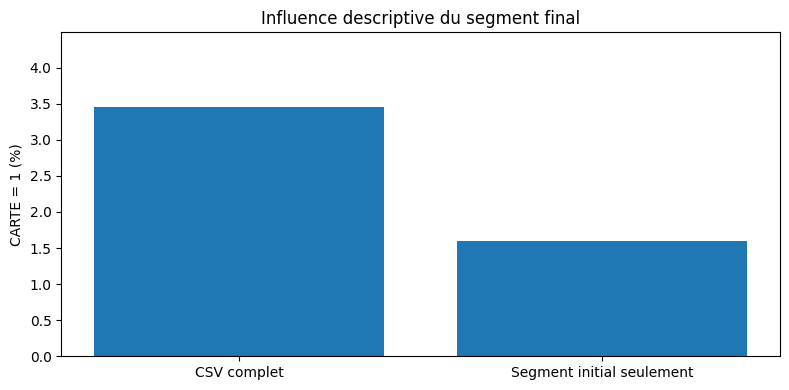

In [6]:
frequence_carte = pd.DataFrame({
    'scenario': ['CSV complet', 'Segment initial seulement', 'Segment final seulement'],
    'n': [len(df), len(segment_initial), len(segment_final)],
    'CARTE_pourcentage': [100*df['CARTE'].mean(),
                          100*segment_initial['CARTE'].mean(),
                          100*segment_final['CARTE'].mean()]
})
display(frequence_carte.round(2))
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(frequence_carte['scenario'][:2], frequence_carte['CARTE_pourcentage'][:2])
ax.set(ylabel='CARTE = 1 (%)', title='Influence descriptive du segment final')
ax.set_ylim(0, max(frequence_carte['CARTE_pourcentage'][:2])*1.3)
plt.tight_layout()
plt.show()

## 7. Analyse des valeurs manquantes de `SEXE`

Selon le dictionnaire, `SEXE` correspond à « Sexe_Leader_foyer ». Nous analysons d'abord le taux global, puis d'éventuels écarts entre groupes. **Ces écarts ne prouvent pas à eux seuls le mécanisme MCAR/MAR/MNAR.**

In [7]:
def resume_manquants(nom, sous_ensemble):
    return {'population': nom, 'lignes': len(sous_ensemble),
            'sexe_manquant': int(sous_ensemble['SEXE'].isna().sum()),
            'pourcentage': round(100*sous_ensemble['SEXE'].isna().mean(), 3)}

n_premiers = round(len(segment_initial)*0.1)
comparaison_manquants = pd.DataFrame([
    resume_manquants('Ensemble', df),
    resume_manquants('Segment initial', segment_initial),
    resume_manquants('Segment final', segment_final),
    resume_manquants('Segment initial: CREDHAB = 0', segment_initial.query('CREDHAB == 0')),
    resume_manquants('Segment initial: CREDHAB = 1', segment_initial.query('CREDHAB == 1')),
    resume_manquants('Premiers 10 %: segment initial', segment_initial.iloc[:n_premiers]),
    resume_manquants('Autres 90 %: segment initial', segment_initial.iloc[n_premiers:])
])
display(comparaison_manquants)
print('Modalités de SEXE dans le CSV complet :')
display(df.SEXE.value_counts(dropna=False))

,population,lignes,sexe_manquant,pourcentage
0,Ensemble,73930,1283,1.735
1,Segment initial,72531,1283,1.769
2,Segment final,1399,0,0.000
3,Segment initial: CREDHAB = 0,51629,1161,2.249
4,Segment initial: CREDHAB = 1,20902,122,0.584
5,Premiers 10 %: segment initial,7253,410,5.653
6,Autres 90 %: segment initial,65278,873,1.337


Modalités de SEXE dans le CSV complet :


SEXE
M      44481
F      28166
NaN     1283
Name: count, dtype: int64

## 8. Décisions en suspens et prochaines étapes

1. Demander si `id` doit être unique et si des observations répétées sont attendues.
2. Demander la provenance et le statut du segment final (1 399 lignes à configuration de produits unique).
3. Demander l'utilisation prévue de `SEXE`, ses valeurs manquantes et la pertinence de cette variable pour l'objectif demandé.
4. Garder le CSV complet et l'analyse du segment initial séparés ; **ne pas supprimer ou imputer avant d'avoir une justification**.
5. Après réponse de l'enseignant, préparer `02_preparation_donnees.ipynb` puis l'analyse de Data Mining adaptée à la consigne.